# Few-Shot Signer Style Generation: Learning a New Signer's Style from 5 Clips

**Idea.** My thesis separated *what character* is written from *whose handwriting style* it is, and generated new characters from five examples. Here the same idea is applied to sign language: separate *which sign* is performed from *who performs it*.

**Question.** If a sign language recognizer has never seen a signer, can a few-shot generative model learn that signer's style from only 5 clips, create extra training samples in that style, and make recognition better for that signer?

**Plan**
1. Download MediaPipe landmarks of WLASL videos from Kaggle with `kagglehub` (no login), and the official WLASL annotation file (gloss and signer id for every video).
2. Use the 100 most common signs (WLASL100). Hold out a group of signers completely. For each held-out signer, 5 clips are the *support set* (the few-shot examples) and the rest are the test clips.
3. Train a style-conditioned VAE on the other signers: a style encoder averages the embeddings of 5 support clips (as in my thesis), a gloss embedding gives the content, and a small discriminator adds adversarial supervision for more realistic motion.
4. Test whether the style vector really carries signer information.
5. Train a recognizer under four conditions and compare accuracy on the unseen signers:
   **A** real training data, **B** A + the 5 support clips, **C** B + synthetic clips in the target signer's style, **D** B + the same number of synthetic clips in a *random* signer's style (control).

If C beats D, the gain comes from the style and not just from having more data.

**Runtime:** Colab T4 GPU. About 30 to 60 minutes, most of it for the download.

In [1]:
# 1. Install packages
!pip -q install -U kagglehub

In [2]:
# 2. Settings
import os, re, json, glob, random, collections, urllib.request
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import torch, torch.nn as nn, torch.nn.functional as F
from tqdm.auto import tqdm

SEED           = 42
N_GLOSSES      = 100     # WLASL100
T_FRAMES       = 32      # every clip is resampled to this many frames
PCA_DIM        = 96
K_SHOT         = 5       # support clips per signer (few-shot style)
TEST_SIGNER_FRAC = 0.25
MIN_CLIPS_TEST_SIGNER = 10
GEN_STEPS      = 4000
GEN_PER_GLOSS  = 2       # synthetic clips per gloss per test signer
CLS_EPOCHS     = 30
N_SEEDS        = 3       # recognizer runs per condition
OUT_DIR = '/content/signer_style'
os.makedirs(OUT_DIR, exist_ok=True)

def set_seed(s):
    random.seed(s); np.random.seed(s); torch.manual_seed(s); torch.cuda.manual_seed_all(s)
set_seed(SEED)
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print('Device:', device)

Device: cuda


## Helper functions: WLASL annotations, landmark loading, resampling, normalisation, PCA

In [3]:
import os, re, json, glob, random, collections
import numpy as np

def norm_vid(k):
    base = os.path.splitext(os.path.basename(str(k)))[0]
    d = re.sub(r'\D', '', base)
    return d.zfill(5) if d else None

def load_wlasl_meta(json_path):
    meta = {}
    data = json.load(open(json_path))
    for rank, entry in enumerate(data):
        for inst in entry['instances']:
            meta[norm_vid(inst['video_id'])] = dict(gloss=entry['gloss'], gloss_rank=rank,
                                                    signer=int(inst['signer_id']),
                                                    fstart=int(inst.get('frame_start', 1)),
                                                    fend=int(inst.get('frame_end', -1)))
    return meta

def as_sequence(arr):
    """Turn one landmark array into (T, N, C). Returns None if the shape is not usable."""
    a = np.asarray(arr, dtype=np.float32)
    if a.ndim == 3:
        return a
    if a.ndim == 2:
        T, F = a.shape
        for C in (3, 2, 4):
            if F % C == 0:
                return a.reshape(T, F // C, C)
    return None

def load_landmarks(npz_path, wanted_ids, max_videos=None):
    """Read a landmarks .npz and return {video_id: (T, N, C)} for the wanted ids."""
    z = np.load(npz_path, allow_pickle=True)
    keys = list(z.keys())
    print(f'{os.path.basename(npz_path)}: {len(keys)} arrays, first keys: {keys[:5]}')
    seqs = {}
    if len(keys) > 20:                       # one array per video
        for k in keys:
            vid = norm_vid(k)
            if vid in wanted_ids:
                s = as_sequence(z[k])
                if s is not None and len(s) >= 4:
                    seqs[vid] = s
            if max_videos and len(seqs) >= max_videos:
                break
    else:                                    # a few big arrays: try to find ids + data
        arrays = {k: z[k] for k in keys}
        for k, v in arrays.items():
            print('   ', k, getattr(v, 'shape', None), getattr(v, 'dtype', None))
        id_key = next((k for k in keys if 'id' in k.lower() or 'name' in k.lower()), None)
        data_key = next((k for k in keys if k != id_key and arrays[k].dtype == object or arrays[k].ndim >= 3), None)
        if id_key is None or data_key is None:
            raise ValueError('Unknown npz layout. Please send the printed keys and shapes.')
        for vid_raw, arr in zip(arrays[id_key], arrays[data_key]):
            vid = norm_vid(vid_raw)
            if vid in wanted_ids:
                s = as_sequence(arr)
                if s is not None and len(s) >= 4:
                    seqs[vid] = s
    return seqs

def resample(seq, T):
    idx = np.linspace(0, len(seq) - 1, T)
    lo, hi = np.floor(idx).astype(int), np.ceil(idx).astype(int)
    w = (idx - lo)[:, None, None]
    return (1 - w) * seq[lo] + w * seq[hi]

def center_scale(seq):
    """Per-clip normalisation of position and size, but keeps how the signer moves."""
    s = seq.astype(np.float32).copy()
    s[~np.isfinite(s)] = np.nan
    s[np.all(s == 0, axis=-1)] = np.nan          # MediaPipe stores missing points as zeros
    xy = s[..., :2]
    c = np.nanmean(xy.reshape(-1, 2), 0)
    sc = np.nanstd(xy.reshape(-1, 2)) + 1e-6
    s[..., :2] = (xy - c) / sc
    if s.shape[-1] > 2:
        s[..., 2:] = s[..., 2:] / sc
    return np.nan_to_num(s, nan=0.0)

class PCA:
    def fit(self, X, k):
        self.mu = X.mean(0)
        U, S, Vt = np.linalg.svd(X - self.mu, full_matrices=False)
        self.W = Vt[:k]
        self.explained = (S[:k] ** 2).sum() / (S ** 2).sum()
        return self
    def transform(self, X): return (X - self.mu) @ self.W.T
    def inverse(self, Z): return Z @ self.W + self.mu

print('helpers OK')

helpers OK


## Step 1. Download the data

* **Landmarks:** *MuteMotion: WLASL MediaPipe Encoded* (`abd0kamel/mutemotion-output`), MediaPipe landmarks extracted from the WLASL videos. Public, so `kagglehub` needs no login.
* **Annotations:** `WLASL_v0.3.json` from the official WLASL GitHub repository. It gives the gloss and **signer id** of every video. If GitHub is not reachable, the same file is downloaded alone from the Kaggle dataset `risangbaskoro/wlasl-processed`.

In [4]:
import kagglehub

lm_dir = kagglehub.dataset_download('abd0kamel/mutemotion-output')
npz_files = sorted(glob.glob(os.path.join(lm_dir, '**', '*.npz'), recursive=True), key=os.path.getsize)
print('landmark files:', [(os.path.basename(f), round(os.path.getsize(f) / 1e6, 1)) for f in npz_files])
assert npz_files, 'No .npz file found in the Kaggle download.'

json_path = os.path.join(OUT_DIR, 'WLASL_v0.3.json')
if not os.path.exists(json_path):
    try:
        urllib.request.urlretrieve('https://raw.githubusercontent.com/dxli94/WLASL/master/start_kit/WLASL_v0.3.json', json_path)
    except Exception as e:
        print('GitHub failed, trying Kaggle:', e)
        p = kagglehub.dataset_download('risangbaskoro/wlasl-processed', path='WLASL_v0.3.json')
        json_path = p if p.endswith('.json') else os.path.join(p, 'WLASL_v0.3.json')
meta = load_wlasl_meta(json_path)
wanted = {v for v, m in meta.items() if m['gloss_rank'] < N_GLOSSES}
print(f'WLASL annotations: {len(meta)} videos, {len(wanted)} in WLASL{N_GLOSSES}')

# The smallest landmark file usually keeps only pose and hand points, which is what we need.
seqs = {}
for f in npz_files:
    try:
        seqs = load_landmarks(f, wanted)
    except Exception as e:
        print('could not read', os.path.basename(f), e); continue
    if len(seqs) > 200:
        print('using', os.path.basename(f)); break
print(f'loaded {len(seqs)} WLASL{N_GLOSSES} clips with landmarks')
assert len(seqs) > 200, 'Too few clips loaded. Please share the printed keys and shapes.'
ex = next(iter(seqs.values())); print('example clip shape (T, N, C):', ex.shape)

100%|██████████| 13.3G/13.3G [13:12<00:00, 18.0MB/s]

Extracting files...


landmark files: [('labels.npz', 2.7), ('landmarks_V2.npz', 2700.0), ('landmarks_V1.npz', 2722.5), ('landmarks_V3.npz', 8922.0)]
WLASL annotations: 21083 videos, 2038 in WLASL100
labels.npz: 2000 arrays, first keys: ['a', 'a lot', 'abdomen', 'able', 'about']
landmarks_V2.npz: 21083 arrays, first keys: ['8881', '15071', '7860', '3982', '13332']
using landmarks_V2.npz
loaded 647 WLASL100 clips with landmarks
example clip shape (T, N, C): (55, 180, 3)


## Step 2. Preprocess, split signers and reduce dimension

In [5]:
vids, X_raw = [], []
for v, s in seqs.items():
    m = meta[v]
    if m['fend'] > 0 and m['fend'] <= len(s):           # cut the clip to the annotated sign
        s = s[max(m['fstart'] - 1, 0): m['fend']]
    if len(s) < 4: continue
    clip = center_scale(resample(s, T_FRAMES))
    if (np.abs(clip) < 1e-6).mean() > 0.6:              # mostly missing landmarks
        continue
    vids.append(v); X_raw.append(clip.reshape(T_FRAMES, -1))
X_raw = np.stack(X_raw).astype(np.float32)
GLOSSES = sorted({meta[v]['gloss'] for v in vids})
g2i = {g: i for i, g in enumerate(GLOSSES)}
y = np.array([g2i[meta[v]['gloss']] for v in vids])
signer = np.array([meta[v]['signer'] for v in vids])
print('clips:', X_raw.shape, '| glosses:', len(GLOSSES), '| signers:', len(set(signer)))

# hold out whole signers
cnt = collections.Counter(signer)
eligible = sorted([s for s, c in cnt.items() if c >= MIN_CLIPS_TEST_SIGNER])
rng = np.random.RandomState(SEED)
n_test = max(5, int(TEST_SIGNER_FRAC * len(eligible)))
TEST_SIGNERS = sorted(rng.choice(eligible, size=min(n_test, len(eligible)), replace=False).tolist())
is_test = np.isin(signer, TEST_SIGNERS)
train_idx = np.where(~is_test)[0]
support_idx, query_idx = {}, []
for s in TEST_SIGNERS:
    idx = rng.permutation(np.where(signer == s)[0])
    support_idx[s] = idx[:K_SHOT]; query_idx += idx[K_SHOT:].tolist()
query_idx = np.array(query_idx)
all_support = np.concatenate(list(support_idx.values()))
print(f'test signers: {len(TEST_SIGNERS)} | train clips: {len(train_idx)} | support clips: {len(all_support)} | test clips: {len(query_idx)}')

# PCA fitted on training signers only, then standardised
pca = PCA().fit(X_raw[train_idx].reshape(-1, X_raw.shape[-1]), PCA_DIM)
print(f'PCA keeps {100 * pca.explained:.1f}% of the variance')
Z = pca.transform(X_raw.reshape(-1, X_raw.shape[-1])).reshape(len(X_raw), T_FRAMES, PCA_DIM)
z_mu, z_sd = Z[train_idx].reshape(-1, PCA_DIM).mean(0), Z[train_idx].reshape(-1, PCA_DIM).std(0) + 1e-6
X = ((Z - z_mu) / z_sd).astype(np.float32)
D = X.shape[-1]; N_CLASSES = len(GLOSSES)

def to_landmarks(x):
    # standardised PCA space -> (T, N, C) landmarks, for plotting
    flat = pca.inverse(x * z_sd + z_mu)
    return flat.reshape(len(x), -1, ex.shape[-1])

clips: (641, 32, 540) | glosses: 39 | signers: 56
test signers: 5 | train clips: 384 | support clips: 25 | test clips: 232
PCA keeps 100.0% of the variance


## Step 3. Style-conditioned VAE with adversarial supervision

* **Style encoder:** a GRU embeds each of the 5 support clips, and the style vector is their **mean** (the same design as my thesis FS-CVAE).
* **Content:** a learned gloss embedding.
* **Decoder:** generates a 32-frame landmark sequence from a latent code, the gloss and the style.
* **Discriminator:** a small GRU that judges whether a sequence looks real (adversarial supervision, as in Dr. Behzad's UNet-VAE), switched on after a warm-up.
* **Training is episodic:** each episode takes one training signer, uses 5 of their clips as support, and reconstructs a *different* clip of the same signer. The support clips are other signs, so the style vector must carry *how* the person signs, not *what* they sign.

training signers usable for episodes: 19


StyleCVAE:   0%|          | 0/4000 [00:00<?, ?it/s]

step 500: rec 0.5316 | kl 98.32
step 1000: rec 0.2597 | kl 76.94
step 1500: rec 0.2339 | kl 68.89
step 2000: rec 0.2114 | kl 67.86
step 2500: rec 0.1868 | kl 67.88
step 3000: rec 0.1679 | kl 66.40
step 3500: rec 0.1536 | kl 64.39
step 4000: rec 0.1438 | kl 63.59


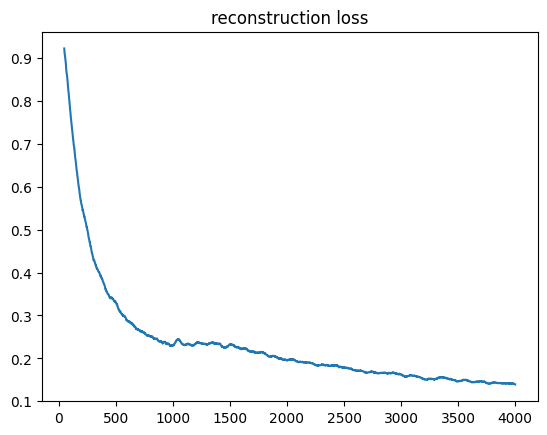

In [6]:
class SeqEncoder(nn.Module):
    def __init__(self, d_in, d_out, cond=0, hidden=128):
        super().__init__()
        self.gru = nn.GRU(d_in + cond, hidden, batch_first=True, bidirectional=True)
        self.out = nn.Linear(2 * hidden, d_out)
    def forward(self, x, c=None):
        if c is not None:
            x = torch.cat([x, c.unsqueeze(1).expand(-1, x.size(1), -1)], -1)
        h, _ = self.gru(x)
        return self.out(h.mean(1))

class StyleCVAE(nn.Module):
    def __init__(self, D, n_gloss, T, S=64, G=64, Zd=32, H=192):
        super().__init__()
        self.T, self.Zd = T, Zd
        self.style_enc = SeqEncoder(D, S)
        self.gloss_emb = nn.Embedding(n_gloss, G)
        self.enc = SeqEncoder(D, H, cond=S + G)
        self.mu, self.lv = nn.Linear(H, Zd), nn.Linear(H, Zd)
        self.pos = nn.Parameter(torch.randn(1, T, 32) * 0.1)
        self.dec_in = nn.Linear(Zd + S + G, H)
        self.dec = nn.GRU(H + 32, H, num_layers=2, batch_first=True)
        self.dec_out = nn.Linear(H, D)
    def style(self, support):                    # (B, K, T, D) -> (B, S)
        B, K = support.shape[:2]
        e = self.style_enc(support.reshape(B * K, *support.shape[2:])).reshape(B, K, -1)
        return e.mean(1)
    def decode(self, z, g, s):
        c = self.dec_in(torch.cat([z, self.gloss_emb(g), s], -1))
        inp = torch.cat([c.unsqueeze(1).expand(-1, self.T, -1), self.pos.expand(z.size(0), -1, -1)], -1)
        h, _ = self.dec(inp)
        return self.dec_out(h)
    def forward(self, x, g, s):
        h = self.enc(x, torch.cat([s, self.gloss_emb(g)], -1))
        mu, lv = self.mu(h), self.lv(h).clamp(-8, 8)
        z = mu + torch.randn_like(mu) * torch.exp(0.5 * lv)
        return self.decode(z, g, s), mu, lv

class Discriminator(nn.Module):
    def __init__(self, D, n_gloss, G=32):
        super().__init__()
        self.emb = nn.Embedding(n_gloss, G)
        self.net = SeqEncoder(D, 1, cond=G, hidden=96)
    def forward(self, x, g):
        return self.net(x, self.emb(g)).squeeze(-1)

Xt = torch.tensor(X, device=device); yt = torch.tensor(y, device=device)
train_by_signer = collections.defaultdict(list)
for i in train_idx:
    train_by_signer[signer[i]].append(i)
episode_signers = [s for s, l in train_by_signer.items() if len(l) >= K_SHOT + 1]
print('training signers usable for episodes:', len(episode_signers))

def sample_episodes(B):
    sup, qry = [], []
    for s in np.random.choice(episode_signers, B):
        pick = np.random.choice(train_by_signer[s], K_SHOT + 1, replace=False)
        sup.append(pick[:K_SHOT]); qry.append(pick[K_SHOT])
    return torch.tensor(np.array(sup), device=device), torch.tensor(np.array(qry), device=device)

gen = StyleCVAE(D, N_CLASSES, T_FRAMES).to(device)
disc = Discriminator(D, N_CLASSES).to(device)
opt_g = torch.optim.Adam(gen.parameters(), lr=1e-3)
opt_d = torch.optim.Adam(disc.parameters(), lr=2e-4)
BETA_MAX, LAMBDA_VEL, LAMBDA_ADV, ADV_START = 0.05, 0.5, 0.02, 1000
log = collections.defaultdict(list)

for step in tqdm(range(GEN_STEPS), desc='StyleCVAE'):
    sup, q = sample_episodes(64)
    xq, gq = Xt[q], yt[q]
    s = gen.style(Xt[sup])
    xh, mu, lv = gen(xq, gq, s)
    rec = F.mse_loss(xh, xq)
    vel = F.mse_loss(xh[:, 1:] - xh[:, :-1], xq[:, 1:] - xq[:, :-1])
    kl = (-0.5 * (1 + lv - mu.pow(2) - lv.exp())).sum(1).mean()
    beta = BETA_MAX * min(1.0, step / 1500)
    loss = rec + LAMBDA_VEL * vel + beta * kl / D
    if step >= ADV_START:
        # generator tries to fool the discriminator (non-saturating loss)
        loss = loss + LAMBDA_ADV * F.binary_cross_entropy_with_logits(disc(xh, gq), torch.ones(len(q), device=device))
    opt_g.zero_grad(); loss.backward(); nn.utils.clip_grad_norm_(gen.parameters(), 1.0); opt_g.step()
    if step >= ADV_START - 200:
        d_real = disc(xq, gq); d_fake = disc(xh.detach(), gq)
        d_loss = F.binary_cross_entropy_with_logits(d_real, torch.ones_like(d_real)) + \
                 F.binary_cross_entropy_with_logits(d_fake, torch.zeros_like(d_fake))
        opt_d.zero_grad(); d_loss.backward(); opt_d.step(); log['d'].append(d_loss.item())
    log['rec'].append(rec.item()); log['kl'].append(kl.item())
    if (step + 1) % 500 == 0:
        print(f"step {step + 1}: rec {np.mean(log['rec'][-500:]):.4f} | kl {np.mean(log['kl'][-500:]):.2f}")
gen.eval()
plt.plot(pd.Series(log['rec']).rolling(50).mean()); plt.title('reconstruction loss'); plt.show()

## Step 4. Does the style vector really carry signer information?

For every unseen signer we predict their test clips from the gloss and the style vector only (latent set to its mean). We compare the error when the style comes from **the same signer's** 5 support clips with the error when it comes from **another** unseen signer. If the own style gives a lower error, the model has learned something about how that person signs.

In [7]:
@torch.no_grad()
def style_of(idx):
    return gen.style(Xt[torch.tensor(idx, device=device)][None])

@torch.no_grad()
def predict(gloss_idx, style_vec):
    n = len(gloss_idx)
    z = torch.zeros(n, gen.Zd, device=device)
    return gen.decode(z, torch.tensor(gloss_idx, device=device), style_vec.expand(n, -1))

own, other = [], []
for s in TEST_SIGNERS:
    q = query_idx[signer[query_idx] == s]
    if len(q) == 0: continue
    xq = Xt[torch.tensor(q, device=device)]
    e_own = F.mse_loss(predict(y[q], style_of(support_idx[s])), xq).item()
    others = [o for o in TEST_SIGNERS if o != s]
    e_oth = np.mean([F.mse_loss(predict(y[q], style_of(support_idx[o])), xq).item() for o in others])
    own.append(e_own); other.append(e_oth)
own, other = np.array(own), np.array(other)
wins = (own < other).mean()
print(f'prediction error with own style   : {own.mean():.4f}')
print(f'prediction error with other style : {other.mean():.4f}')
print(f'own style is better for {100 * wins:.0f}% of unseen signers')
pd.DataFrame({'signer': TEST_SIGNERS[:len(own)], 'own_style_mse': own, 'other_style_mse': other}).to_csv(
    os.path.join(OUT_DIR, 'style_check.csv'), index=False)

prediction error with own style   : 1.8723
prediction error with other style : 1.8729
own style is better for 80% of unseen signers


## Step 5. Generate synthetic clips for every unseen signer

synthetic clips per condition: 390


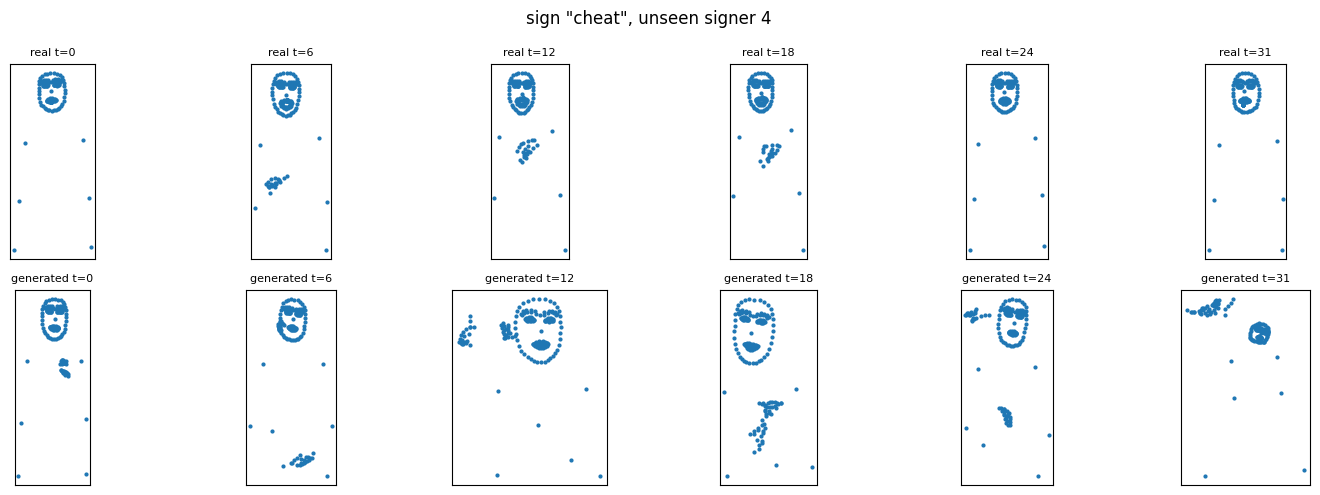

In [8]:
@torch.no_grad()
def generate(style_vec, per_gloss=GEN_PER_GLOSS):
    g = torch.arange(N_CLASSES, device=device).repeat_interleave(per_gloss)
    z = torch.randn(len(g), gen.Zd, device=device)
    return gen.decode(z, g, style_vec.expand(len(g), -1)).cpu().numpy(), g.cpu().numpy()

syn_target_X, syn_target_y, syn_random_X, syn_random_y = [], [], [], []
for s in TEST_SIGNERS:
    xs, gs = generate(style_of(support_idx[s]))
    syn_target_X.append(xs); syn_target_y.append(gs)
    rs = np.random.choice(episode_signers)                 # control: style of a random training signer
    xr, gr = generate(style_of(np.random.choice(train_by_signer[rs], K_SHOT, replace=False)))
    syn_random_X.append(xr); syn_random_y.append(gr)
syn_target_X, syn_target_y = np.concatenate(syn_target_X), np.concatenate(syn_target_y)
syn_random_X, syn_random_y = np.concatenate(syn_random_X), np.concatenate(syn_random_y)
print('synthetic clips per condition:', len(syn_target_X))

# plot: a real test clip next to a generated clip of the same sign in the same signer's style
q = query_idx[0]; s = signer[q]
gen_clip = predict([y[q]], style_of(support_idx[s])).cpu().numpy()
real_lm, gen_lm = to_landmarks(X[q])[None][0], to_landmarks(gen_clip[0])
fig, axes = plt.subplots(2, 6, figsize=(15, 5))
for k, t in enumerate(np.linspace(0, T_FRAMES - 1, 6).astype(int)):
    for row, (lm, name) in enumerate([(real_lm, 'real'), (gen_lm, 'generated')]):
        ax = axes[row, k]; ax.scatter(lm[t, :, 0], -lm[t, :, 1], s=4)
        ax.set_title(f'{name} t={t}', fontsize=8); ax.set_xticks([]); ax.set_yticks([]); ax.set_aspect('equal')
plt.suptitle(f'sign "{GLOSSES[y[q]]}", unseen signer {s}'); plt.tight_layout()
plt.savefig(os.path.join(OUT_DIR, 'real_vs_generated.png'), dpi=150); plt.show()

## Step 6. Recognition on unseen signers under four conditions

The recognizer is a bidirectional GRU. Every condition is trained with the same settings and `N_SEEDS` different seeds.

| Condition | Training data |
|---|---|
| A | real clips of training signers |
| B | A + the 5 support clips of each unseen signer |
| C | B + synthetic clips in the **target** signer's style |
| D | B + the same number of synthetic clips in a **random** signer's style (control) |

In [9]:
class Recognizer(nn.Module):
    def __init__(self, D, n_cls):
        super().__init__()
        self.enc = SeqEncoder(D, 128); self.drop = nn.Dropout(0.3); self.fc = nn.Linear(128, n_cls)
    def forward(self, x): return self.fc(self.drop(F.relu(self.enc(x))))

def train_and_eval(Xtr, ytr, seed):
    set_seed(seed)
    model = Recognizer(D, N_CLASSES).to(device)
    opt = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-3)
    Xtr_t, ytr_t = torch.tensor(Xtr, device=device), torch.tensor(ytr, device=device)
    for ep in range(CLS_EPOCHS):
        model.train()
        for b in torch.randperm(len(Xtr_t), device=device).split(64):
            xb = Xtr_t[b] + 0.05 * torch.randn_like(Xtr_t[b])       # light noise augmentation
            loss = F.cross_entropy(model(xb), ytr_t[b], label_smoothing=0.1)
            opt.zero_grad(); loss.backward(); opt.step()
    model.eval()
    with torch.no_grad():
        logits = model(Xt[torch.tensor(query_idx, device=device)])
    yq = torch.tensor(y[query_idx], device=device)
    top1 = (logits.argmax(1) == yq).float()
    top5 = (logits.topk(5, 1).indices == yq[:, None]).any(1).float()
    return top1.cpu().numpy(), top5.cpu().numpy()

base_X, base_y = X[train_idx], y[train_idx]
conds = {
    'A: real':                 (base_X, base_y),
    'B: + 5 support clips':    (np.concatenate([base_X, X[all_support]]), np.concatenate([base_y, y[all_support]])),
}
conds['C: + target-style synthetic'] = (np.concatenate([conds['B: + 5 support clips'][0], syn_target_X]),
                                        np.concatenate([conds['B: + 5 support clips'][1], syn_target_y]))
conds['D: + random-style synthetic'] = (np.concatenate([conds['B: + 5 support clips'][0], syn_random_X]),
                                        np.concatenate([conds['B: + 5 support clips'][1], syn_random_y]))

# rare signs: the third of glosses with the fewest training clips
train_count = np.bincount(base_y, minlength=N_CLASSES)
rare = set(np.argsort(train_count)[: N_CLASSES // 3])
rare_mask = np.array([y[i] in rare for i in query_idx])

results, per_seed = [], {}
for name, (Xc, yc) in conds.items():
    t1s, t5s, rares = [], [], []
    for k in range(N_SEEDS):
        t1, t5 = train_and_eval(Xc.astype(np.float32), yc, SEED + k)
        t1s.append(t1.mean()); t5s.append(t5.mean()); rares.append(t1[rare_mask].mean())
        per_seed[(name, k)] = t1
    results.append({'condition': name, 'train clips': len(Xc),
                    'top-1 %': 100 * np.mean(t1s), 'top-1 sd': 100 * np.std(t1s),
                    'top-5 %': 100 * np.mean(t5s), 'rare-sign top-1 %': 100 * np.mean(rares)})
    print(f"{name:32s} top-1 {100 * np.mean(t1s):5.2f} ± {100 * np.std(t1s):.2f} | top-5 {100 * np.mean(t5s):5.2f}")
res_df = pd.DataFrame(results); res_df.to_csv(os.path.join(OUT_DIR, 'recognition_results.csv'), index=False)
res_df.round(2)

A: real                          top-1 37.93 ± 1.86 | top-5 66.24
B: + 5 support clips             top-1 37.64 ± 1.42 | top-5 68.10
C: + target-style synthetic      top-1 39.80 ± 0.81 | top-5 65.23
D: + random-style synthetic      top-1 37.64 ± 0.89 | top-5 64.66


,condition,train clips,top-1 %,top-1 sd,top-5 %,rare-sign top-1 %
0,A: real,384,37.930000,1.86,66.239998,19.340000
1,B: + 5 support clips,409,37.639999,1.42,68.099998,19.750000
2,C: + target-style synthetic,799,39.799999,0.81,65.230003,19.750000
3,D: + random-style synthetic,799,37.639999,0.89,64.660004,17.700001


C: minus D:: +2.16 points (95% CI -0.72 to +5.03)
C: minus B:: +2.16 points (95% CI -1.01 to +5.03)


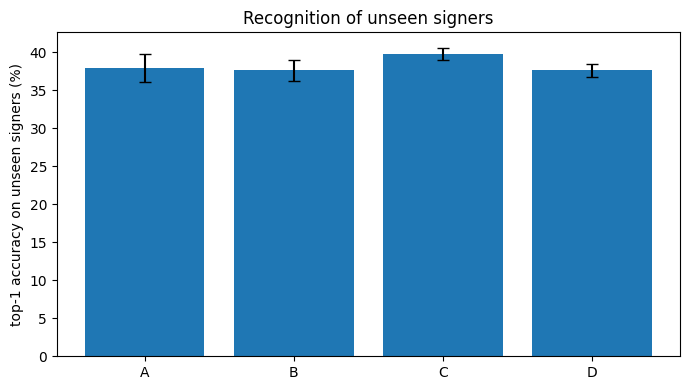

In [10]:
# paired bootstrap: C vs D and C vs B, on the same test clips (seed-averaged correctness)
def seed_avg(name): return np.mean([per_seed[(name, k)] for k in range(N_SEEDS)], 0)
def paired_ci(a, b, n=2000):
    d = a - b; idx = np.random.randint(0, len(d), (n, len(d)))
    m = d[idx].mean(1); return d.mean(), np.percentile(m, [2.5, 97.5])
for x, z in [('C: + target-style synthetic', 'D: + random-style synthetic'),
             ('C: + target-style synthetic', 'B: + 5 support clips')]:
    m, (lo, hi) = paired_ci(seed_avg(x), seed_avg(z))
    print(f'{x[:2]} minus {z[:2]}: {100 * m:+.2f} points (95% CI {100 * lo:+.2f} to {100 * hi:+.2f})')

plt.figure(figsize=(7, 4))
plt.bar(res_df['condition'].str[:1], res_df['top-1 %'], yerr=res_df['top-1 sd'], capsize=4)
plt.ylabel('top-1 accuracy on unseen signers (%)'); plt.title('Recognition of unseen signers')
plt.tight_layout(); plt.savefig(os.path.join(OUT_DIR, 'recognition.png'), dpi=150); plt.show()

## Step 7. Save everything

In [11]:
torch.save({'gen': gen.state_dict(), 'glosses': GLOSSES, 'pca_mu': pca.mu, 'pca_W': pca.W,
            'z_mu': z_mu, 'z_sd': z_sd, 'test_signers': TEST_SIGNERS}, os.path.join(OUT_DIR, 'style_cvae.pt'))
import shutil
shutil.make_archive('/content/signer_style_results', 'zip', OUT_DIR)
print('Saved: /content/signer_style_results.zip')
try:
    from google.colab import files
    files.download('/content/signer_style_results.zip')
except Exception:
    pass

Saved: /content/signer_style_results.zip


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## Notes for writing up the results

* **Signer-independent split.** Test signers never appear in training, except for their 5 support clips, which every condition from B onward also gets. This keeps the comparison fair.
* **The key comparison is C against D.** Both add the same number of synthetic clips. If C is higher, the benefit comes from the signer's style, not just from more data.
* **Step 4** is a direct test of the style vector, independent of the recognizer.
* **Rare signs:** the last column shows whether synthetic data helps the signs with the fewest training clips, which links to the singleton problem in the Isharah dataset.
* **Limits.** One dataset (WLASL100, American Sign Language), MediaPipe landmarks only (no RGB), one recognizer, and a small number of test signers. A natural next step is the Isharah dataset and Arabic Sign Language.